In [ ]:
import os
import random
import time   # ⬅️ NEW
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torchvision.models import resnet50
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

from huggingface_hub import hf_hub_download
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import kagglehub
from collections import defaultdict
torch.manual_seed(42)
random.seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


In [ ]:
import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Dataset path:", path)


Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset path: /kaggle/input/chest-xray-pneumonia


In [ ]:
data_root = Path(path)
base_dir = data_root / "chest_xray" if (data_root / "chest_xray").exists() else data_root

train_dir = base_dir / "train"
test_dir  = base_dir / "test"


In [ ]:
image_size = 224
batch_size = 64
num_workers = 4 if torch.cuda.is_available() else 2

train_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406],
                         std=[0.229,0.224,0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406],
                         std=[0.229,0.224,0.225]),
])

In [ ]:
full_train_dataset = ImageFolder(train_dir, transform=train_transform)
targets = full_train_dataset.targets
indices = list(range(len(targets)))

# stratified split for train/val
train_idx, val_idx = train_test_split(
    indices,
    test_size=0.10,
    stratify=targets,
    random_state=42
)
class_to_train_indices = defaultdict(list)
for idx in train_idx:
    label = targets[idx]
    class_to_train_indices[label].append(idx)

# Decide target size (undersample to minority class count)
min_count = min(len(idxs) for idxs in class_to_train_indices.values())
print("Per-class counts BEFORE downsampling:", {k: len(v) for k, v in class_to_train_indices.items()})
print("Downsampling each class to:", min_count)

balanced_train_idx = []
for cls, idxs in class_to_train_indices.items():
    if len(idxs) > min_count:
        sampled = random.sample(idxs, min_count)
    else:
        sampled = list(idxs)
    balanced_train_idx.extend(sampled)

random.shuffle(balanced_train_idx)
print("Balanced train size:", len(balanced_train_idx))

# Create datasets/loaders:
# Important: full_train_dataset must be the ImageFolder built from train_dir (same class ordering)
train_dataset = Subset(full_train_dataset, balanced_train_idx)

# Validation uses the original (not-balanced) indices and eval_transform
val_dataset = Subset(ImageFolder(train_dir, transform=eval_transform), val_idx)

# Test unchanged
test_dataset = ImageFolder(test_dir, transform=eval_transform)

print(f"Train size: {len(train_dataset)}")
print(f"Val size:   {len(val_dataset)}")
print(f"Test size:  {len(test_dataset)}")

class_names = full_train_dataset.classes
num_classes = len(class_names)
print("Classes:", class_names)

Per-class counts BEFORE downsampling: {1: 3487, 0: 1207}
Downsampling each class to: 1207
Balanced train size: 2414
Train size: 2414
Val size:   522
Test size:  624
Classes: ['NORMAL', 'PNEUMONIA']


In [ ]:
train_loader = DataLoader(
    train_dataset, batch_size=batch_size,
    shuffle=True, num_workers=num_workers
)

val_loader = DataLoader(
    val_dataset, batch_size=batch_size,
    shuffle=False, num_workers=num_workers
)

test_loader = DataLoader(
    test_dataset, batch_size=batch_size,
    shuffle=False, num_workers=num_workers
)



/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [ ]:
backbone = resnet50(pretrained=False)

backbone.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
backbone.maxpool = nn.Identity()
feat_dim = backbone.fc.in_features
backbone.fc = nn.Identity()

local_path = hf_hub_download(
    repo_id="edadaltocg/resnet50_simclr_cifar100",
    filename="pytorch_model.bin"
)

state_dict = torch.load(local_path, map_location="cpu")
state_dict = {
    k.replace("backbone.", ""): v
    for k, v in state_dict.items()
    if k.replace("backbone.", "") in backbone.state_dict()
}

backbone.load_state_dict(state_dict, strict=False)
backbone = backbone.to(device)
print("✅ CIFAR-pretrained backbone loaded")

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


✅ CIFAR-pretrained backbone loaded


In [ ]:
class LinearEvalModel(nn.Module):
    def __init__(self, backbone, feature_dim, num_classes, freeze_backbone=True):
        super().__init__()
        self.backbone = backbone
        if freeze_backbone:
            for p in self.backbone.parameters():
                p.requires_grad = False
        self.classifier = nn.Linear(feature_dim, num_classes)

    def forward(self, x):
        feat = self.backbone(x)
        return self.classifier(feat)

model = LinearEvalModel(backbone, feat_dim, num_classes, freeze_backbone=True)
model = model.to(device)


In [ ]:
class_counts = np.bincount(targets)
class_weights = torch.tensor(
    1. / class_counts, dtype=torch.float
).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-3, weight_decay=1e-6
)


In [ ]:
def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)

            total_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(1) == yb).sum().item()
            total += xb.size(0)

    return total_loss / total, correct / total

In [ ]:
patience = 3
min_delta = 1e-4
best_val_loss = float('inf')
epochs_no_improve = 0


In [ ]:
epochs = 6
train_losses, val_losses = [], []

start_time = time.time()

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")
    for xb, yb in pbar:
        xb, yb = xb.to(device), yb.to(device)

        logits = model(xb)
        loss = criterion(logits, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        pbar.set_postfix(train_loss=running_loss / (pbar.n + 1))

    train_loss = running_loss / len(train_loader)
    val_loss, val_acc = evaluate(model, val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(f"Epoch {epoch+1}: "
          f"Train Loss={train_loss:.4f}, "
          f"Val Loss={val_loss:.4f}, "
          f"Val Acc={val_acc:.4f}")

    # ===== EARLY STOPPING =====
    if val_loss < best_val_loss - min_delta:
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save(model.state_dict(), "best_model.pt")  # optional
    else:
        epochs_no_improve += 1
        print(f"Early stopping counter: {epochs_no_improve}/{patience}")

    if epochs_no_improve >= patience:
        print("\n⏹️ Early stopping triggered")
        break

end_time = time.time()
total_time = end_time - start_time

print("\n==============================")
print(f"Total training time: {total_time/60:.2f} minutes")
print(f"Average time per epoch: {total_time/(epoch+1):.2f} seconds")
print("==============================\n")


Epoch 1/6: 100%|██████████| 38/38 [02:02<00:00,  3.23s/it, train_loss=0.566]


Epoch 1: Train Loss=0.5659, Val Loss=0.7393, Val Acc=0.2567


Epoch 2/6: 100%|██████████| 38/38 [02:05<00:00,  3.31s/it, train_loss=0.48]


Epoch 2: Train Loss=0.4804, Val Loss=0.6382, Val Acc=0.2874


Epoch 3/6: 100%|██████████| 38/38 [02:05<00:00,  3.30s/it, train_loss=0.415]


Epoch 3: Train Loss=0.4151, Val Loss=0.5417, Val Acc=0.5192


... (2 outputs left out)

Epoch 5/6: 100%|██████████| 38/38 [02:04<00:00,  3.29s/it, train_loss=0.33]


Epoch 5: Train Loss=0.3302, Val Loss=0.4634, Val Acc=0.6743


Epoch 6/6: 100%|██████████| 38/38 [02:04<00:00,  3.29s/it, train_loss=0.302]


Epoch 6: Train Loss=0.3019, Val Loss=0.4177, Val Acc=0.7548

Total training time: 15.32 minutes
Average time per epoch: 153.18 seconds



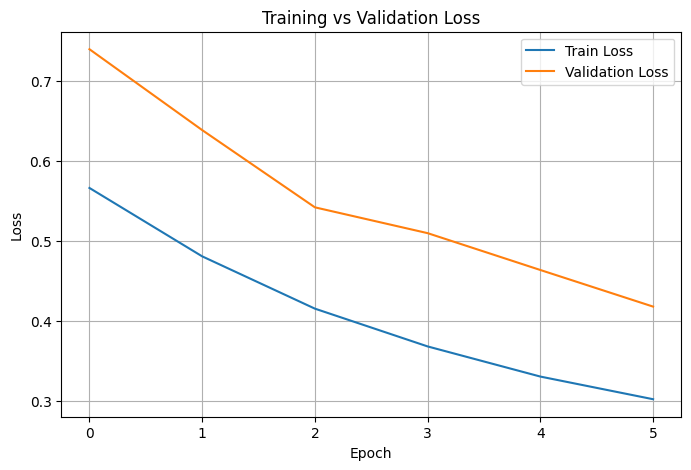

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
test_loss, test_acc = evaluate(model, test_loader)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Test Loss: 0.5283
Test Accuracy: 0.7532


In [ ]:
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        preds = model(xb).argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(yb.numpy())

print("\nClassification Report:\n")
print(classification_report(all_labels, all_preds, target_names=class_names))


Classification Report:

              precision    recall  f1-score   support

      NORMAL       0.62      0.90      0.73       234
   PNEUMONIA       0.92      0.67      0.77       390

    accuracy                           0.75       624
   macro avg       0.77      0.78      0.75       624
weighted avg       0.80      0.75      0.76       624



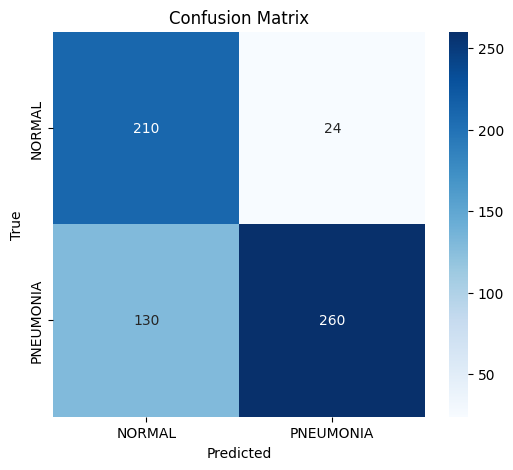

In [ ]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm, annot=True, fmt="d",
    xticklabels=class_names,
    yticklabels=class_names,
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


In [ ]:
os.makedirs("checkpoints", exist_ok=True)
torch.save(model.state_dict(), "checkpoints/linear_eval_simclr_cxr.pt")
print("✅ Model saved")

✅ Model saved


In [ ]:
infer_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406],
                         std=[0.229,0.224,0.225]),
])

In [ ]:

def predict_single(img_path):
    img = Image.open(img_path).convert("RGB")
    x = infer_transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(x)
        probs = torch.softmax(logits, dim=1)[0]

    return {
        "prediction": class_names[probs.argmax().item()],
        "probabilities": {
            class_names[i]: float(probs[i]) for i in range(len(class_names))
        }
    }


In [ ]:
result = predict_single("/content/images.jpeg") #Normal
result2 = predict_single("/content/images (1).jpeg")# Pneumonia
result3 = predict_single("/content/images (2).jpeg") #Pneumonia
result4 = predict_single("/content/images (4) .jpg") # Normal
print(result)
print(result2)
print(result3)
print(result4)


FileNotFoundError: [Errno 2] No such file or directory: '/content/images.jpeg'